# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:

# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
# mostrar las primeras 5 filas de plans
plans = pd.read_csv('/datasets/plans.csv')

In [4]:

# mostrar las primeras 5 filas de users
users.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
import pandas as pd

plans = pd.read_csv('/datasets/plans.csv')
users_latam = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users_latam.shape)
print("usage", usage.shape)






plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info() 
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info() 
users_latam.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info() 
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users

print(users_latam.isna().sum())
print(users_latam.isna().mean())

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage

print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

Dataset users

city: 469 valores nulos (11,73%). Representa una proporción moderada de datos faltantes, por lo que se recomienda investigar e imputar si es posible mediante información relacionada; en caso contrario, mantenerlos como nulos.
churn_date: 3534 valores nulos (88,35%). No se considera un error, ya que probablemente indica clientes que siguen activos. Se recomienda conservar los nulos y no imputarlos.

Dataset usage

date: 50 valores nulos (0,125%). La proporción es mínima, por lo que pueden eliminarse esos registros o mantenerse para revisión sin afectar significativamente el análisis.
duration: 22076 valores nulos (55,19%). Los nulos parecen estar asociados a registros de mensajes de texto, por lo que corresponden a la lógica del negocio y deben conservarse.
length: 17896 valores nulos (44,74%). Los nulos parecen corresponder a llamadas telefónicas, por lo que también deben mantenerse y no imputarse automáticamente.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

Dataset users:

city: 469 valores nulos (11,73%).
churn_date: 3534 valores nulos (88,35%).

Dataset usage:

date: 50 valores nulos (0,125%).
duration: 22076 valores nulos (55,19%).
length: 17896 valores nulos (44,74%).
  
- Indica qué harías: ¿imputar, eliminar, ignorar?

city (11,73%) → Imputar o investigar. Al estar entre 5% y 30%, conviene analizar posibles patrones antes de decidir cómo completar los valores faltantes.
churn_date (88,35%) → Ignorar/conservar. Los nulos probablemente representan clientes activos, por lo que tienen significado dentro del negocio y no deben eliminarse ni imputarse.
date (0,125%) → Eliminar o imputar de forma simple. La cantidad es muy baja y su impacto en el análisis sería mínimo.
duration (55,19%) → Ignorar/conservar. Los nulos parecen corresponder a registros de mensajes de texto, donde no existe duración de llamada.
length (44,74%) → Ignorar/conservar. Los nulos parecen corresponder a llamadas telefónicas, donde no hay longitud de mensaje.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users

users_latam[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` ... Haz doble clic en este bloque y escribe qué ves.
- La columna `age` ...

In [13]:
# explorar columnas numéricas de usage

usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [14]:
# explorar columnas categóricas de users
users_latam['city'].unique()
users_latam['plan'].unique() 

array(['Basico', 'Premium'], dtype=object)

- La columna `city` ...
- La columna `plan` ...

In [15]:
# explorar columna categórica de usage
usage['type'].unique() # completa el código
users_latam['plan'].value_counts() 
usage['type'].value_counts()

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` ...


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

Columna age: Se observa un valor mínimo de -999, que corresponde a un valor inválido o sentinel porque no existen edades negativas. Recomiendo reemplazarlo por NaN y posteriormente imputarlo o analizarlo según el contexto del estudio.

Columna city: Se detectó la presencia de valores faltantes y registros anómalos como "?", que pueden representar información desconocida. Recomiendo convertir estos valores a NaN para tratarlos correctamente durante la limpieza de datos.

Columna plan: Solo aparecen los valores Basico y Premium, por lo que no se observan inconsistencias. No requiere acciones correctivas.

Columna type: Solo contiene las categorías call y text, que son coherentes con el tipo de servicio registrado. No requiere acciones correctivas.

Columnas duration y length: Presentan valores nulos, pero estos parecen ser consecuencia de la naturaleza de los registros (llamadas o mensajes) y no de errores de calidad. Recomiendo mantener estos valores tal como están y considerarlos válidos para el análisis.

Conclusión

El principal valor sentinel detectado corresponde a age = -999, mientras que en city existen valores inválidos o faltantes que deben tratarse como nulos. El resto de las variables analizadas presentan valores coherentes con la lógica del negocio y no requieren correcciones inmediatas.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?

age: Se detectó un valor mínimo de -999, lo que constituye un valor inválido o sentinel, ya que una edad no puede ser negativa.
city: En pasos anteriores se observó la presencia de valores faltantes e indicios de registros anómalos (como el carácter ?), que pueden considerarse valores inválidos.
plan: Solo presenta las categorías Basico y Premium, sin valores extraños o inconsistentes.
type: Solo contiene las categorías call y text, sin evidencias de valores inválidos.
duration y length: Aunque presentan valores nulos, estos parecen explicarse por la lógica del negocio (llamadas y mensajes) y no por errores de captura.

- ¿Qué acción tomarías?

age (-999): Reemplazar el valor -999 por NaN y posteriormente imputar o analizar los registros afectados.
city (valor "?" y nulos): Sustituir el símbolo ? por NaN para tratarlo como dato faltante y evaluar posteriormente una estrategia de imputación.
plan: No requiere tratamiento, ya que los valores son válidos y consistentes.
type: No requiere tratamiento, ya que únicamente contiene categorías válidas.
duration y length: Mantener los valores nulos porque parecen representar situaciones normales según el tipo de interacción registrada.


### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:

# Convertir a fecha la columna `reg_date` de users

users_latam['reg_date'] = pd.to_datetime(users_latam['reg_date'], errors='coerce')

In [17]:

# Convertir a fecha la columna `date` de usage

usage['date'] = pd.to_datetime(usage['date'], errors='coerce')

In [18]:

# Revisar los años presentes en `reg_date` de users

print(users_latam['reg_date'].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

In [19]:

print(usage['date'].dt.year.value_counts().sort_index())

2024.0    39950
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

En reg_date se observan registros correspondientes a los años 2022, 2023 y 2024, que son coherentes con el período de análisis. Sin embargo, también aparecen 40 registros del año 2026, lo que constituye una fecha fuera de rango, ya que el dataset solo contiene información hasta 2024. Recomiendo investigar estos registros y corregirlos si existe información disponible; en caso contrario, marcarlos como valores faltantes (NaN) o excluirlos del análisis para evitar sesgos.

En date todos los registros válidos corresponden al año 2024, lo que resulta consistente con el período analizado. No se observan años imposibles ni fechas futuras entre los valores válidos. Recomiendo mantener estos registros sin modificaciones y tratar únicamente los valores faltantes detectados previamente

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)

Sí, en reg_date aparece el año 2026 en 40 registros, lo que está fuera del rango esperado.
En date no se observan años fuera de rango; todos los registros corresponden a 2024.

- ¿Qué harías con ellas?

Revisar y corregir los registros de 2026 si es posible identificar el año real.
Si no es posible validarlos, reemplazar esas fechas por NaN o excluir esos registros del análisis.
Mantener sin cambios las fechas de date, ya que no presentan inconsistencias.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:

# Reemplazar -999 por la mediana de age

age_mediana = users_latam.loc[users_latam['age'] != -999, 'age'].median()
users_latam['age'] = users_latam['age'].replace(-999, age_mediana)

# Verificar cambios
users_latam['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city

users_latam['city'] = users_latam['city'].replace('?', pd.NA)

# Verificar cambios
users_latam['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [22]:
# Marcar fechas futuras como NA para reg_date

users_latam.loc[
    users_latam['reg_date'].dt.year > 2024,
    'reg_date'
] = pd.NaT

# Verificar cambios
users_latam['reg_date'].dt.year.value_counts().sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:

# Verificación MAR en usage para duration

print(usage.groupby('type')['duration'].apply(lambda x: x.isna().mean()))

type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [24]:

# Verificación MAR en usage para length

print(usage.groupby('type')['length'].apply(lambda x: x.isna().mean()))

type
call    0.99933
text    0.00000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Los valores nulos en duration y length dependen directamente de la columna type.

Para los registros de llamadas (call), la duración es relevante mientras que la longitud del mensaje no aplica, por lo que length aparece como nulo.

Para los registros de mensajes (message), la longitud del mensaje es relevante mientras que la duración de llamada no aplica, por lo que duration aparece como nulo.

Estos valores faltantes no corresponden a errores de calidad de datos, sino a información no aplicable según el tipo de actividad registrada. Por esta razón, los valores nulos se conservan y no serán imputados ni eliminados.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
usage["is_call"] = (usage["type"] == "call").astype(int)

# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:

# Renombrar columnas

usage_agg.columns = [
    "user_id",
    "cant_mensajes",
    "cant_llamadas",
    "cant_minutos_llamada"
]

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:

# Combinar la tabla agregada con el dataset de usuarios

user_profile = users_latam.merge(
    usage_agg,
    on="user_id",
    how="left"
)

user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:

user_profile[['age',
              'cant_mensajes',
              'cant_llamadas',
              'cant_minutos_llamada']].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [29]:

round(user_profile['plan'].value_counts(normalize=True) * 100, 2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

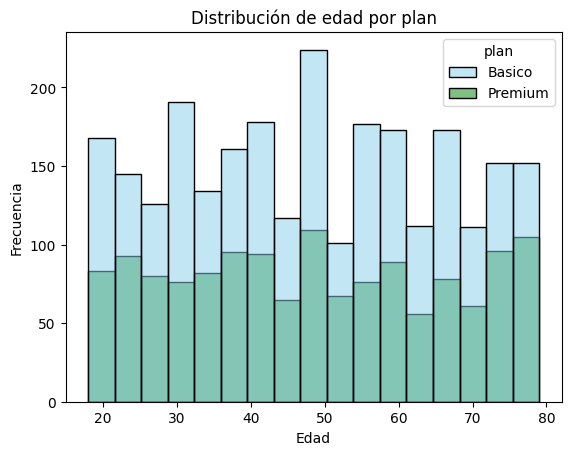

In [30]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Distribución de edad por plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución ...

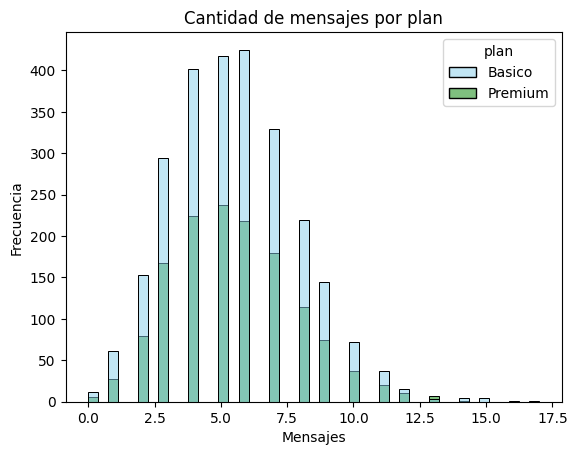

In [31]:
# Histograma para visualizar la cant_mensajes

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Cantidad de mensajes por plan')
plt.xlabel('Mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- ....

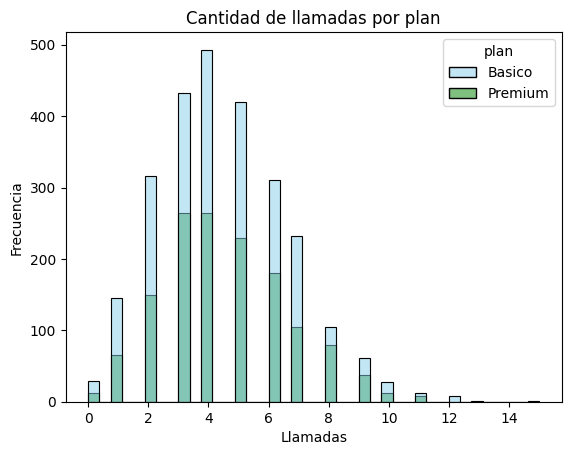

In [32]:
# Histograma para visualizar la cant_llamadas

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Cantidad de llamadas por plan')
plt.xlabel('Llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución ...

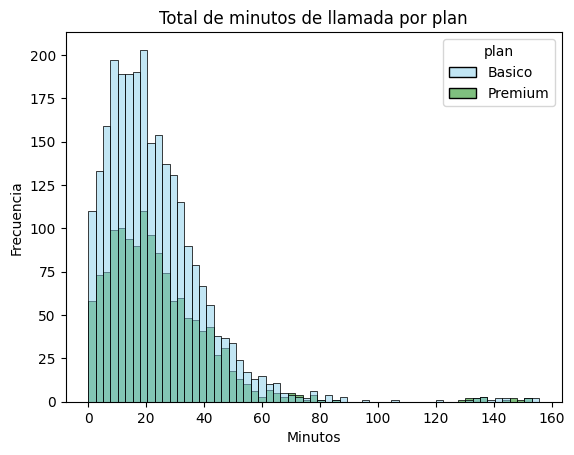

In [33]:
# Histograma para visualizar la cant_minutos_llamada

import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Total de minutos de llamada por plan')
plt.xlabel('Minutos')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- ...

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

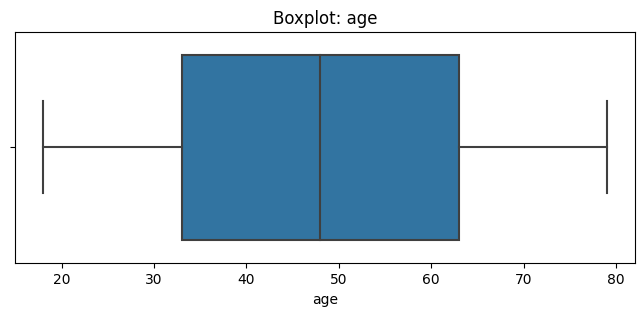

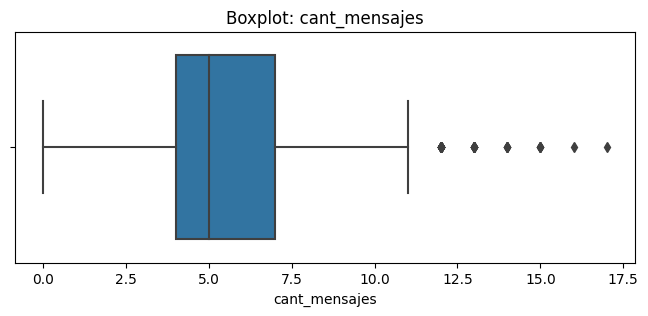

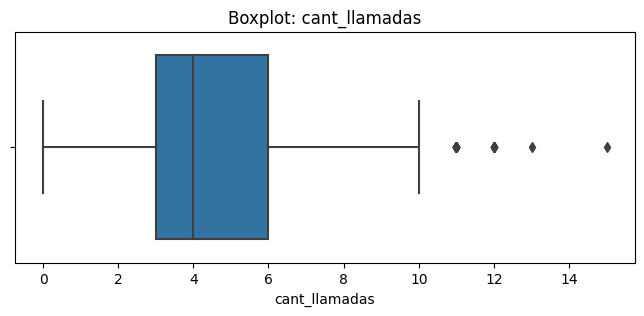

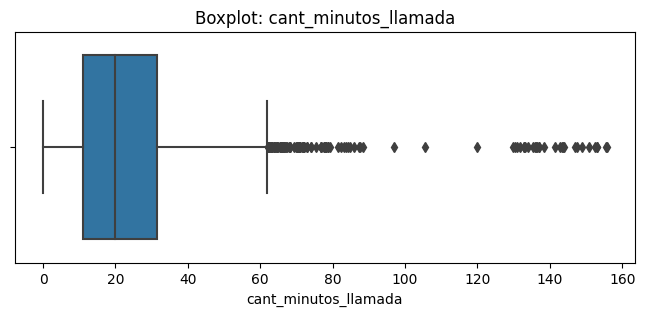

In [34]:

# Visualizando usando BoxPlot

columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_numericas:
    plt.figure(figsize=(8,3))
    sns.boxplot(x=user_profile[col])
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: ...(presenta o no outliers)
- cant_mensajes: ...
- cant_llamadas: ...
- cant_minutos_llamada: ...

Age:
No se observan outliers relevantes. Los valores de edad se encuentran dentro de rangos razonables para la población analizada.

cant_mensajes:
Se observan valores altos identificados como outliers según el método IQR. Sin embargo, pueden representar usuarios intensivos y no necesariamente errores de captura.

cant_llamadas:
Existen usuarios con una cantidad de llamadas considerablemente superior al promedio. Estos registros podrían corresponder a comportamientos reales de uso y se recomienda mantenerlos.

cant_minutos_llamada:
Se identifican outliers en la parte superior de la distribución. Dado que el objetivo es analizar el comportamiento de los clientes, estos valores aportan información relevante y no deberían eliminarse sin evidencia de error.

In [35]:

# Calcular límites con el método IQR

columnas_limites = [
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_superior = Q3 + 1.5 * IQR

    print(f'{col}')
    print(f'Límite superior: {limite_superior}')
    print(f'Máximo: {user_profile[col].max()}')
    print()

cant_mensajes
Límite superior: 11.5
Máximo: 17.0

cant_llamadas
Límite superior: 10.5
Máximo: 15.0

cant_minutos_llamada
Límite superior: 61.8575
Máximo: 155.69



In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?

Se identifican valores por encima del límite superior de 11.5 mensajes, alcanzando un máximo de 17 mensajes.

Interpretación: Estos registros pueden corresponder a usuarios con una actividad de mensajería más intensa que el promedio y no existe evidencia de errores de captura.

Decisión: Mantener los outliers.

- cant_llamadas: mantener o no outliers, porqué?

Se observan valores superiores al límite de 10.5 llamadas, llegando hasta 15 llamadas.

Interpretación: Estos usuarios representan comportamientos legítimos de uso intensivo del servicio telefónico.

Decisión: Mantener los outliers.

- cant_minutos_llamada: mantener o no outliers, porqué?

Es la variable con mayor presencia de valores atípicos. El límite superior calculado es de 61.86 minutos, mientras que algunos usuarios alcanzan los 155.69 minutos.

Interpretación: La presencia de estos valores es consistente con la distribución observada anteriormente, donde existe un grupo reducido de usuarios con consumos significativamente mayores al promedio.

Decisión: Mantener los outliers.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:

# Crear columna grupo_uso

user_profile['grupo_uso'] = 'Alto uso'

user_profile.loc[
    (user_profile['cant_llamadas'] < 10) &
    (user_profile['cant_mensajes'] < 10),
    'grupo_uso'
] = 'Uso medio'

user_profile.loc[
    (user_profile['cant_llamadas'] < 5) &
    (user_profile['cant_mensajes'] < 5),
    'grupo_uso'
] = 'Bajo uso'

In [38]:
# verificar cambios
user_profile['grupo_uso'].value_counts()

Uso medio    2943
Bajo uso      778
Alto uso      279
Name: grupo_uso, dtype: int64

### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:

# Crear columna grupo_edad

user_profile['grupo_edad'] = 'Adulto Mayor'

user_profile.loc[
    user_profile['age'] < 60,
    'grupo_edad'
] = 'Adulto'

user_profile.loc[
    user_profile['age'] < 30,
    'grupo_edad'
] = 'Joven'

In [40]:

# verificar cambios

user_profile.head()

user_profile['grupo_edad'].value_counts()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64

### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

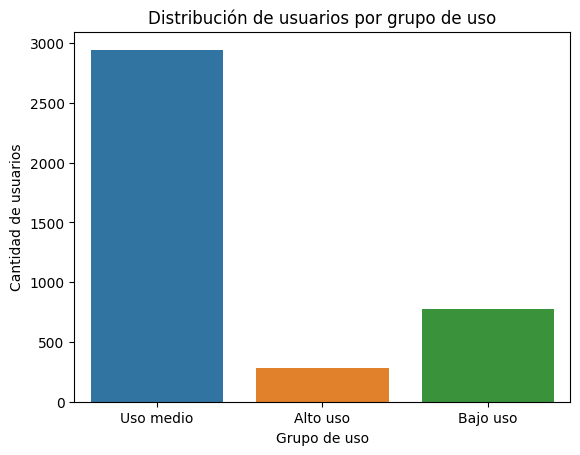

In [41]:

# Visualización de los segmentos por uso

sns.countplot(
    data=user_profile,
    x='grupo_uso'
)

plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

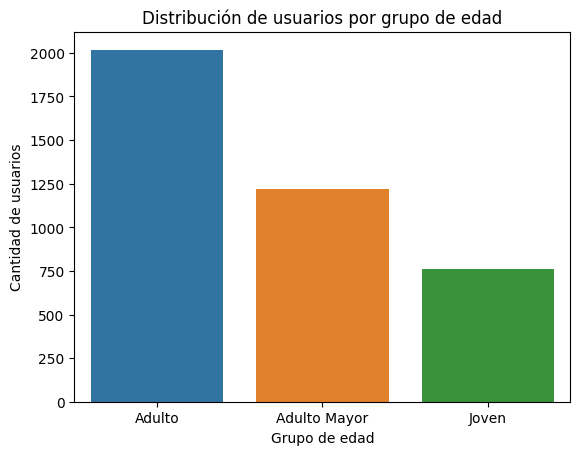

<AxesSubplot:xlabel='grupo_edad', ylabel='count'>

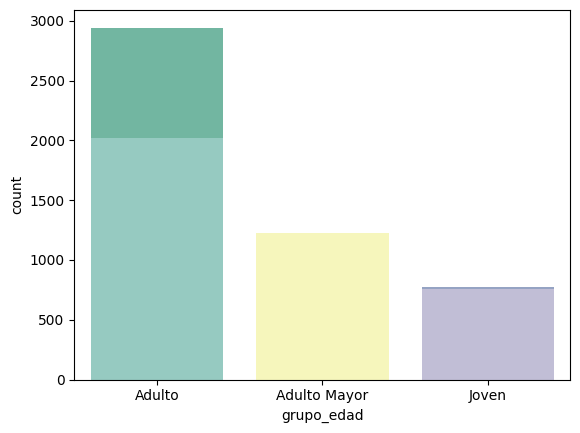

In [42]:

# Visualización de los segmentos por edad

sns.countplot(
    data=user_profile,
    x='grupo_edad'
)

plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show() 
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    palette='Set2'
) 
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    palette='Set3'
)


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


Durante la etapa de exploración y limpieza se identificaron diversos problemas de calidad de datos. En el dataset users_latam se encontraron 469 valores nulos en la columna city (11,73%) y 3534 valores nulos en churn_date (88,35%). También se detectó un valor centinela en la variable age con el valor -999, el cual fue reemplazado por la mediana para evitar distorsiones en el análisis estadístico.

Asimismo, en la columna city se identificaron registros con el valor "?", que fueron convertidos a valores nulos para un tratamiento uniforme. Además, se detectaron 40 registros con fechas del año 2026 en reg_date, las cuales estaban fuera del rango temporal esperado y fueron reemplazadas por valores nulos.

En el dataset usage, las columnas duration y length presentaban una gran cantidad de valores nulos. Sin embargo, tras analizar la variable type, se comprobó que dichos nulos dependían del tipo de actividad registrada (call o text), por lo que correspondían al funcionamiento normal del negocio y no fueron considerados errores.

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?

Se identificaron segmentos tanto por edad como por nivel de uso.

En términos de edad, los clientes fueron clasificados en:

Adulto: 2018 usuarios (50,45%).
Adulto Mayor: 1222 usuarios (30,55%).
Joven: 760 usuarios (19,00%).

En cuanto al nivel de uso:

Uso medio: 2943 usuarios (73,58%).
Bajo uso: 778 usuarios (19,45%).
Alto uso: 279 usuarios (6,98%).

Los resultados muestran que la base de clientes está compuesta principalmente por usuarios adultos con patrones de consumo moderados. Existe además un grupo reducido de clientes con uso intensivo de llamadas y mensajes, mientras que una proporción menor presenta una utilización limitada de los servicios.
  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?

Los clientes clasificados como Alto uso parecen ser los más valiosos para la compañía. Aunque representan solo el 6,98% de la base de usuarios, son quienes registran mayores niveles de consumo en llamadas, mensajes y minutos de uso.

Este segmento tiene un alto potencial comercial porque puede beneficiarse de planes premium, servicios adicionales y programas de fidelización. Además, su nivel de actividad sugiere una mayor probabilidad de generar ingresos recurrentes para la empresa.

Por otro lado, los clientes de Uso medio, que representan cerca del 74% de la cartera, constituyen el segmento más importante en volumen. Cualquier mejora en la oferta dirigida a este grupo podría tener un impacto significativo debido a su tamaño.

➡️ Esto sugiere que el comportamiento de los clientes no es homogéneo y que existen oportunidades para personalizar la oferta comercial según el nivel de consumo y la edad.

- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?

Se identificaron valores atípicos en las variables cant_mensajes, cant_llamadas y cant_minutos_llamada mediante análisis visual con boxplots y validación utilizando el método IQR.

Los usuarios con valores extremos presentan niveles de consumo considerablemente superiores al promedio. Sin embargo, no existe evidencia de que estos registros correspondan a errores de captura o datos inválidos. Por el contrario, representan comportamientos reales de clientes con uso intensivo de los servicios.

Desde una perspectiva de negocio, estos usuarios son especialmente relevantes porque pueden constituir un segmento de alto valor comercial, servir como base para el diseño de planes avanzados y ayudar a identificar oportunidades de fidelización y venta cruzada.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

Se recomienda desarrollar estrategias diferenciadas para cada segmento identificado:

Crear planes premium o beneficios exclusivos dirigidos a los usuarios de Alto uso, incorporando mayores límites de llamadas y mensajes.
Diseñar alternativas más económicas y flexibles para los clientes de Bajo uso, evitando que paguen por servicios que utilizan poco.
Optimizar la oferta principal para el segmento de Uso medio, ya que concentra aproximadamente el 74% de la base de clientes.
Implementar campañas segmentadas por edad, adaptando promociones y beneficios para jóvenes, adultos y adultos mayores.
Desarrollar programas de fidelización para usuarios con consumos elevados, aprovechando su potencial de largo plazo.
Fortalecer los procesos de captura y validación de datos para reducir la aparición de valores centinela, registros incompletos y errores de ingreso.


✍️ **Escribe aquí tu análisis ejecutivo:**

Problemas Detectados en los Datos

Durante la fase de exploración y limpieza se identificaron diversos problemas de calidad de datos que podían afectar la confiabilidad de los resultados.

En el dataset de usuarios se detectaron 469 valores nulos en la variable city (11,73%) y 3534 valores nulos en churn_date (88,35%). Además, se identificó el valor centinela -999 en la variable age, el cual fue reemplazado por la mediana de la distribución para evitar distorsiones estadísticas.

También se encontraron registros con el valor especial "?" en la variable city, los cuales fueron transformados en valores faltantes para garantizar consistencia en el tratamiento de los datos. Adicionalmente, se detectaron registros con fechas fuera del rango esperado en reg_date, correspondientes al año 2026, que fueron corregidos al considerarse inconsistentes con el periodo de análisis.

En el dataset de uso se observó una gran cantidad de valores nulos en las variables duration y length. Sin embargo, el análisis permitió comprobar que dichos nulos dependían del tipo de actividad registrada (call o text), por lo que representan una característica normal de los datos y no errores de captura.

Segmentación de Clientes
Segmentación por Edad

Los clientes fueron clasificados en tres grupos etarios:

Grupo	Usuarios	Participación
Adulto	2018	50,45 %
Adulto Mayor	1222	30,55 %
Joven	760	19,00 %

La mayoría de los clientes pertenece al segmento Adulto, seguido por los Adultos Mayores. Esto indica que la base de clientes de ConnectaTel está compuesta principalmente por usuarios de edad media y avanzada, quienes representan más del 80 % del total.

Esta información resulta especialmente útil para diseñar campañas comerciales, promociones y beneficios adaptados a las características de cada grupo etario.

Segmentación por Nivel de Uso

Los usuarios también fueron segmentados según su intensidad de uso:

Grupo	Usuarios	Participación
Uso medio	2943	73,58 %
Bajo uso	778	19,45 %
Alto uso	279	6,98 %

Los resultados muestran que la mayor parte de la cartera corresponde a clientes con niveles moderados de consumo, mientras que existe un pequeño grupo de usuarios de alto uso que concentra consumos significativamente mayores.

Esta segmentación evidencia que el comportamiento de los clientes no es homogéneo y que existen oportunidades para adaptar la oferta comercial según los patrones reales de utilización de los servicios.

Outliers y Comportamientos de Alto Consumo

El análisis mediante histogramas, boxplots y el método IQR permitió detectar valores atípicos en las variables:

Cantidad de mensajes.
Cantidad de llamadas.
Minutos totales de llamadas.

Estos usuarios presentan niveles de uso considerablemente superiores al promedio. No obstante, tras revisar los registros, no se encontraron evidencias de errores de captura o valores imposibles.

Por esta razón, los outliers fueron conservados en el análisis, ya que representan comportamientos reales de negocio. Desde una perspectiva comercial, estos usuarios constituyen un segmento particularmente interesante debido a su potencial valor económico y a su posible interés en planes más avanzados o beneficios adicionales.

Implicaciones para el Negocio

Los resultados muestran que la cartera de clientes de ConnectaTel está compuesta por segmentos claramente diferenciados tanto en edad como en intensidad de uso.

Por un lado, la empresa cuenta con una amplia base de usuarios de consumo moderado que representa cerca del 74 % de la cartera. Por otro, existe un grupo más reducido de usuarios intensivos cuyo comportamiento podría generar mayores oportunidades de rentabilidad mediante estrategias de fidelización y venta de servicios premium.

Adicionalmente, la importante participación de clientes adultos y adultos mayores sugiere la necesidad de adaptar parte de la propuesta comercial a las características de estos segmentos.

Recomendaciones

Diseñar planes premium orientados a usuarios de alto consumo, incorporando mayores límites de llamadas y mensajería.
Optimizar la oferta dirigida al segmento de uso medio, ya que concentra la mayor parte de los clientes de la compañía.
Crear planes más flexibles y económicos para usuarios de bajo uso, mejorando la relación entre precio y consumo real.
Implementar campañas y promociones segmentadas según grupos de edad, adaptando beneficios y comunicaciones a las necesidades de cada perfil.
Desarrollar estrategias de fidelización para usuarios con consumos elevados, aprovechando su potencial de generación de ingresos.
Fortalecer los procesos de captura y validación de datos para reducir la aparición de valores centinela, registros incompletos y errores de ingreso.

Conclusión Ejecutiva

El análisis permitió transformar los datos operacionales de ConnectaTel en información útil para la toma de decisiones estratégicas. Se identificaron y corrigieron problemas de calidad de datos, se definieron segmentos de clientes por edad y nivel de uso, y se detectaron patrones de consumo diferenciados que aportan una visión más precisa de la cartera de usuarios.

Los hallazgos sugieren que una estrategia basada en segmentación y personalización permitiría optimizar la oferta comercial, mejorar la experiencia de los clientes y maximizar el valor generado por cada segmento. En particular, los usuarios de alto consumo representan una oportunidad relevante para impulsar productos premium, mientras que el amplio segmento de uso medio constituye el principal foco para el crecimiento sostenible de la compañía.


### Análisis ejecutivo

Problemas detectados en los datos

Durante la fase de exploración y limpieza se identificaron diversos problemas de calidad de datos que podían afectar la validez del análisis.

En el dataset de usuarios se detectaron 469 valores nulos en la variable city (11,73%) y 3.534 valores nulos en churn_date (88,35%). Además, se identificaron registros con el valor sentinela -999 en la variable age, los cuales fueron reemplazados por la mediana para evitar distorsiones estadísticas.

También se encontraron registros con el valor especial "?" en la variable city, los cuales fueron tratados como valores faltantes (NA).

En el dataset de uso se observó una alta proporción de valores nulos en las variables duration y length. Sin embargo, tras analizar la relación con la variable type, se concluyó que dichos nulos eran consistentes con la naturaleza de cada registro. Las llamadas registran duración pero no longitud de mensaje, mientras que los mensajes registran longitud pero no duración. Por esta razón, dichos valores se mantuvieron y no fueron considerados errores.

Segmentación de Clientes por Edad

Los usuarios fueron clasificados en tres segmentos etarios:

Jóvenes (menores de 30 años) Adultos (entre 30 y 59 años) Adultos Mayores (60 años o más)

El análisis permitió observar que la base de clientes está compuesta por distintos grupos generacionales con potenciales necesidades de comunicación diferentes. Esta segmentación constituye una herramienta útil para futuras campañas comerciales y para el diseño de productos más adaptados a cada perfil de cliente.

La edad representa una variable relevante para comprender patrones de uso y desarrollar estrategias de personalización de servicios.

Segmentación por Nivel de Uso

Los clientes fueron segmentados en tres categorías según su volumen de llamadas y mensajes:

Bajo uso Uso medio Alto uso

Esta clasificación permitió identificar usuarios con comportamientos significativamente distintos dentro de la base de clientes.

Los segmentos de uso medio y alto resultan especialmente relevantes desde una perspectiva comercial, ya que representan clientes con mayor interacción con el servicio y potencialmente mayor disposición a contratar productos adicionales o planes superiores.

Por otra parte, los usuarios de bajo uso podrían beneficiarse de planes más económicos o flexibles, mejorando su percepción de valor y reduciendo riesgos de abandono.

Outliers y Comportamientos Atípicos

Mediante histogramas, boxplots y el método IQR se identificaron valores atípicos en variables relacionadas con la actividad del usuario, especialmente en:

Cantidad de mensajes. Cantidad de llamadas. Minutos totales de llamadas.

A pesar de encontrarse fuera de los rangos habituales de consumo, estos registros no fueron eliminados debido a que representan comportamientos plausibles dentro del negocio y no existen evidencias de errores de captura.

Desde una perspectiva empresarial, estos usuarios pueden representar clientes de alto valor, perfiles corporativos o consumidores intensivos de los servicios de telecomunicaciones. Por tanto, su comportamiento constituye una fuente importante de información para futuras estrategias de segmentación y fidelización.

Implicaciones para el Negocio

Los resultados indican que la base de clientes de ConnectaTel presenta una elevada heterogeneidad tanto en edad como en intensidad de uso.

No todos los clientes consumen los servicios de la misma manera, por lo que una única propuesta comercial resulta insuficiente para capturar adecuadamente las necesidades de todos los segmentos identificados.

La existencia de usuarios con patrones de consumo muy diferentes sugiere oportunidades para optimizar la oferta comercial mediante una estrategia de segmentación más sofisticada.

Recomendaciones

Diseñar planes diferenciados para usuarios de alto consumo, incorporando mayores beneficios en llamadas y mensajería.

Crear alternativas más económicas y flexibles para usuarios de bajo uso, mejorando la adecuación entre precio y consumo real.

Desarrollar campañas segmentadas por grupos etarios, adaptando promociones y servicios a las características de cada segmento.

Implementar procesos de validación de datos más robustos para prevenir la aparición de valores sentinela y registros inconsistentes.

Analizar en profundidad a los usuarios con consumos extremos, ya que podrían representar oportunidades de fidelización, expansión de servicios o desarrollo de nuevas ofertas comerciales.

Conclusión Ejecutiva

El análisis permitió transformar datos operacionales en información útil para la toma de decisiones. Se identificaron problemas de calidad de datos, se construyeron segmentos de clientes basados en edad y nivel de uso, y se detectaron patrones de consumo diferenciados que evidencian oportunidades de mejora comercial.

En conjunto, los resultados sugieren que una estrategia basada en segmentación y personalización permitiría a ConnectaTel optimizar su oferta de planes, mejorar la experiencia de los clientes y aumentar el valor generado por cada segmento de usuarios.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`